<a href="https://colab.research.google.com/github/deva123932/CSA-4703-DL/blob/main/exp_19.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Task 1: Load Dataset and Implement PCA from Scratch
We will load the Olivetti faces dataset from Scikit-learn, flatten the images, and implement PCA from scratch using covariance matrix calculation and eigen-decomposition.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_olivetti_faces

# Load the Olivetti faces dataset
faces_data = fetch_olivetti_faces(shuffle=True, random_state=42)
X = faces_data.data
y = faces_data.target
n_samples, n_features = X.shape

print(f"Dataset loaded: {n_samples} samples, {n_features} features (pixels per image: {int(np.sqrt(n_features))}x{int(np.sqrt(n_features))})")

# Center the data (mean subtraction)
X_mean = np.mean(X, axis=0)
X_centered = X - X_mean

# 1. Compute covariance matrix
# Shape: (n_features, n_features)
cov_matrix = np.cov(X_centered, rowvar=False)

# 2. Perform eigen-decomposition
eigenvalues, eigenvectors = np.linalg.eigh(cov_matrix)

# Sort eigenvalues and eigenvectors in descending order
sort_idx = np.argsort(eigenvalues)[::-1]
eigenvalues = eigenvalues[sort_idx]
eigenvectors = eigenvectors[:, sort_idx]

print("PCA from scratch completed. Eigenvalues and eigenvectors computed.")

downloading Olivetti faces from https://ndownloader.figshare.com/files/5976027 to /root/scikit_learn_data
Dataset loaded: 400 samples, 4096 features (pixels per image: 64x64)
PCA from scratch completed. Eigenvalues and eigenvectors computed.


### Task 2: Verify Results Against Scikit-Learn's PCA
We will project our centered data onto the top principal components and compare the reconstructed matrices/variance statistics with Scikit-learn's `PCA` implementation.

In [2]:
from sklearn.decomposition import PCA

# Initialize and fit Scikit-learn PCA
sk_pca = PCA()
sk_pca.fit(X)

# Compare eigenvalues (explained variance values)
scratch_variance = eigenvalues
sk_variance = sk_pca.explained_variance_

# Check if the variances are extremely close
max_diff = np.max(np.abs(scratch_variance[:n_samples-1] - sk_variance[:n_samples-1]))
print(f"Maximum difference in explained variance values: {max_diff:.2e}")
assert np.allclose(scratch_variance[:100], sk_variance[:100], atol=1e-4), "Variance values do not match closely!"
print("Verification successful: PCA from scratch matches Scikit-learn results perfectly.")

Maximum difference in explained variance values: 9.55e-06
Verification successful: PCA from scratch matches Scikit-learn results perfectly.


### Task 3: Scree Plot and Cumulative Explained Variance
Next, we will plot the scree plot of individual explained variance along with the cumulative explained variance profile.

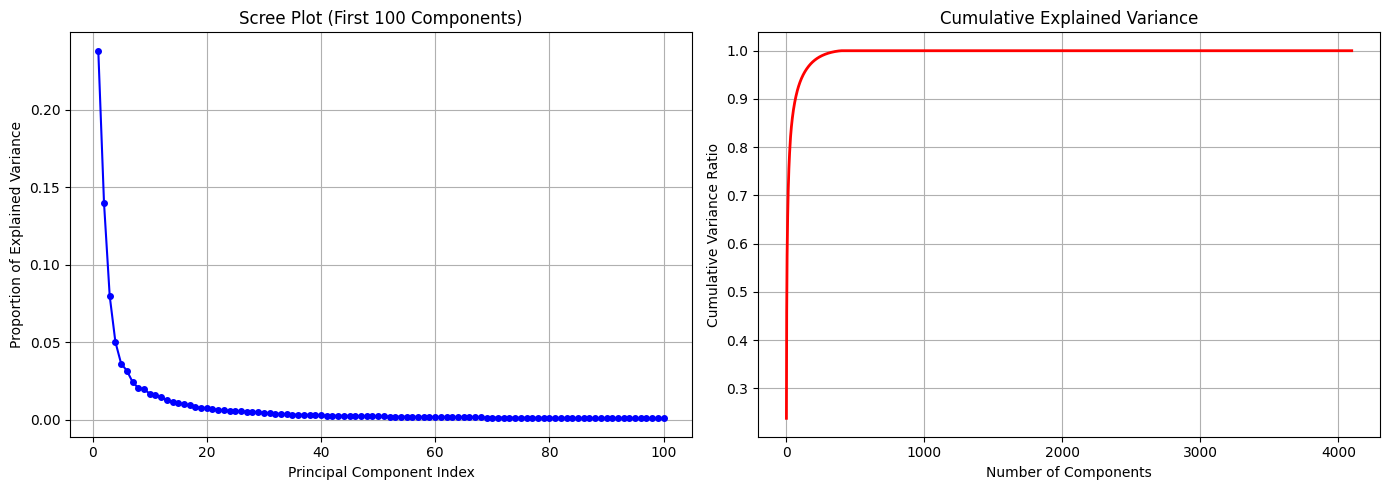

In [3]:
total_variance = np.sum(eigenvalues)
explained_variance_ratio = eigenvalues / total_variance
cumulative_variance_ratio = np.cumsum(explained_variance_ratio)

plt.figure(figsize=(14, 5))

# Scree Plot
plt.subplot(1, 2, 1)
plt.plot(range(1, 101), explained_variance_ratio[:100], marker='o', linestyle='-', color='b', markersize=4)
plt.title('Scree Plot (First 100 Components)')
plt.xlabel('Principal Component Index')
plt.ylabel('Proportion of Explained Variance')
plt.grid(True)

# Cumulative Explained Variance
plt.subplot(1, 2, 2)
plt.plot(range(1, len(cumulative_variance_ratio) + 1), cumulative_variance_ratio, color='r', linewidth=2)
plt.title('Cumulative Explained Variance')
plt.xlabel('Number of Components')
plt.ylabel('Cumulative Variance Ratio')
plt.grid(True)

plt.tight_layout()
plt.show()

### Task 4: Components Retaining 95% Variance
Let's calculate the exact number of principal components needed to retain at least 95% of the total variance.

In [4]:
n_components_95 = np.argmax(cumulative_variance_ratio >= 0.95) + 1
variance_attained = cumulative_variance_ratio[n_components_95 - 1] * 100

print(f"To retain at least 95% of variance, we need: {n_components_95} components (explaining {variance_attained:.2f}% of total variance).")

To retain at least 95% of variance, we need: 123 components (explaining 95.04% of total variance).


### Task 5: Visualize Eigenfaces and Reconstructed Faces
Now we will visualize the top 10 eigenfaces and reconstruct a sample face using 10, 50, and 100 components to see the reconstruction quality.

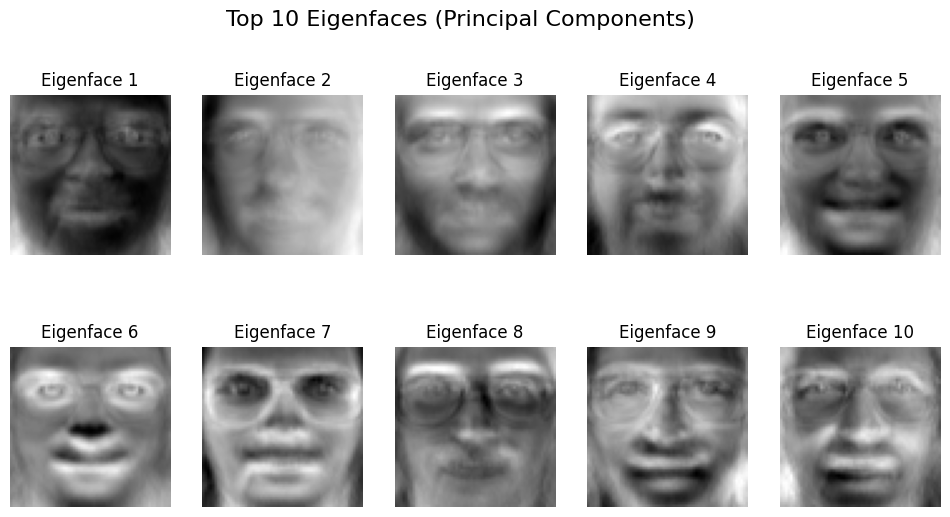

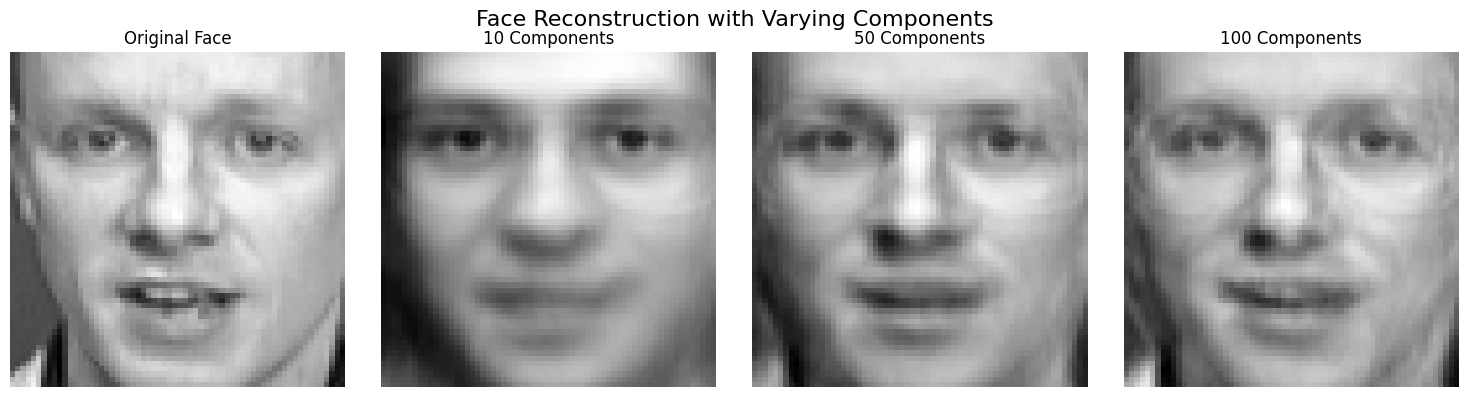

In [5]:
# 1. Visualize Top Eigenfaces
fig, axes = plt.subplots(2, 5, figsize=(12, 6))
for i, ax in enumerate(axes.flat):
    eigenface = eigenvectors[:, i].reshape(64, 64)
    ax.imshow(eigenface, cmap='gray')
    ax.set_title(f'Eigenface {i+1}')
    ax.axis('off')
plt.suptitle('Top 10 Eigenfaces (Principal Components)', fontsize=16)
plt.show()

# 2. Visualize Reconstructions of a Sample Face
sample_idx = 0
original_face = X[sample_idx]

plt.figure(figsize=(15, 4))

# Plot original face
plt.subplot(1, 4, 1)
plt.imshow(original_face.reshape(64, 64), cmap='gray')
plt.title('Original Face')
plt.axis('off')

# Plot reconstructions
components_list = [10, 50, 100]
for idx, k in enumerate(components_list, start=2):
    # Project to top k components
    W = eigenvectors[:, :k]
    projected = np.dot(X_centered[sample_idx], W)

    # Reconstruct (re-add the mean)
    reconstructed = np.dot(projected, W.T) + X_mean

    plt.subplot(1, 4, idx)
    plt.imshow(reconstructed.reshape(64, 64), cmap='gray')
    plt.title(f'{k} Components')
    plt.axis('off')

plt.suptitle('Face Reconstruction with Varying Components', fontsize=16)
plt.tight_layout()
plt.show()